<a href="https://colab.research.google.com/github/saberBenhamda0/Deep_learning_-_Applications_assignments/blob/main/tp1/part1/01_NYSE_Regression_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1 — NYSE regression with PyTorch
**Student:** Saber Ben Hamda · FST Tanger · Master MBD

Predict AAPL next-trading-day closing price from current-day OHLCV, available after market close. Scope: one company, not all NYSE securities. This is an educational forecasting experiment, not an investment strategy.

Dataset: https://www.kaggle.com/datasets/dgawlik/nyse

Workflow: EDA → chronological split → baseline → GridSearchCV → regularization → final evaluation. Outputs are intentionally empty until executed. Regression uses R² instead of undefined classification accuracy. Test data is reserved for the final, frozen experiments.

## 1. Install and import
Run cells in order. Colab CPU is sufficient; GPU is optional. Downloading public Kaggle datasets may require authentication if Kaggle requests it. If download fails, download the CSV manually and use the upload fallback in the next section. The full grid runs 48 fits; reduce the grid only while debugging.

In [10]:
%pip -q install skorch imbalanced-learn kagglehub seaborn

In [11]:
import os, random, copy, json, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from skorch import NeuralNetRegressor, NeuralNetClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTENC
import kagglehub
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
seed_all()
sns.set_theme(style='whitegrid')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
print('PyTorch:', torch.__version__, '| device:', DEVICE)

PyTorch: 2.11.0+cpu | device: cpu


## 2. Download and inspect
Set `TICKER` to another existing symbol if desired. The upload fallback expects `prices-split-adjusted.csv`.

In [12]:
try:
    data_dir = Path(kagglehub.dataset_download('dgawlik/nyse'))
    csv_path = next(data_dir.rglob('prices-split-adjusted.csv'))
except Exception as exc:
    print('Automatic download failed:', exc)
    from google.colab import files
    uploaded = files.upload()
    csv_path = Path(next(k for k in uploaded if k.endswith('.csv')))
df = pd.read_csv(csv_path)
df['date'] = pd.to_datetime(df['date'])
TICKER = 'AAPL'
display(df.head(), df.describe(include='all'))
print(df.shape); df.info()
display(df.isna().sum().to_frame('missing'))
print('Duplicate rows:', df.duplicated().sum())
assert not df.duplicated(['symbol', 'date']).any(), 'Resolve duplicate symbol/date records first.'
stock = df.loc[df.symbol.eq(TICKER)].sort_values('date').copy()
assert len(stock) > 300, 'Choose a ticker with sufficient history.'
features = ['open', 'high', 'low', 'close', 'volume']
stock[features] = stock[features].apply(pd.to_numeric, errors='coerce')
stock = stock.replace([np.inf, -np.inf], np.nan)

100%|██████████| 30.7M/30.7M [00:00<00:00, 207MB/s]

Extracting files...


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


,date,symbol,open,close,low,high,volume
count,851264,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
unique,NaN,501,NaN,NaN,NaN,NaN,NaN
top,NaN,AIV,NaN,NaN,NaN,NaN,NaN
freq,NaN,1762,NaN,NaN,NaN,NaN,NaN
mean,2013-07-21 02:56:29.294037760,NaN,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,NaN,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,NaN,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,NaN,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,NaN,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,NaN,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08


(851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


,missing
date,0
symbol,0
open,0
close,0
low,0
high,0
volume,0


Duplicate rows: 0


## 3. Exploratory data analysis
Describe trend, volatility, skewed volume and highly correlated prices. Whole-dataset EDA below is descriptive; do not choose model settings from test-period patterns.

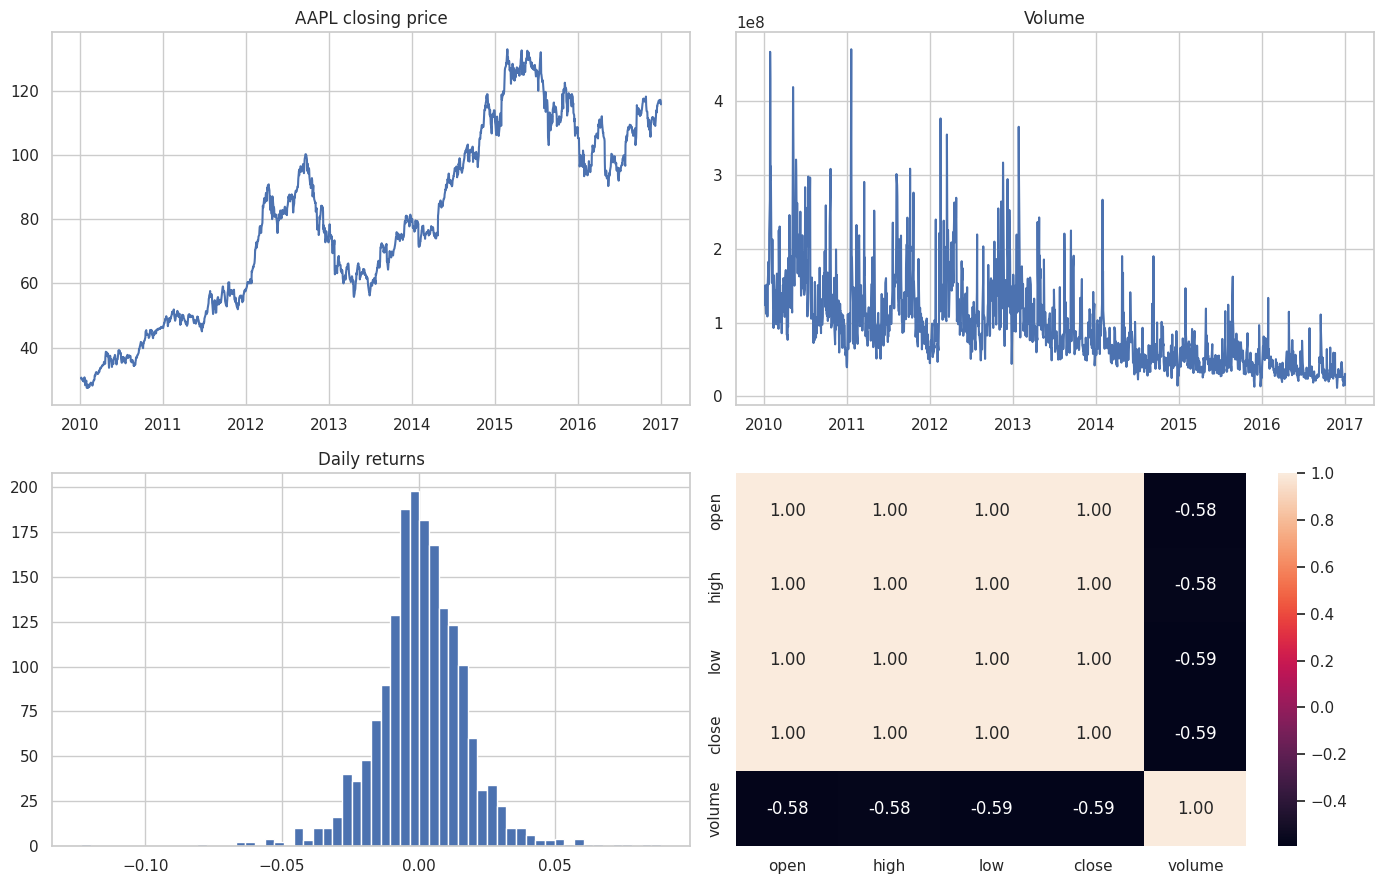

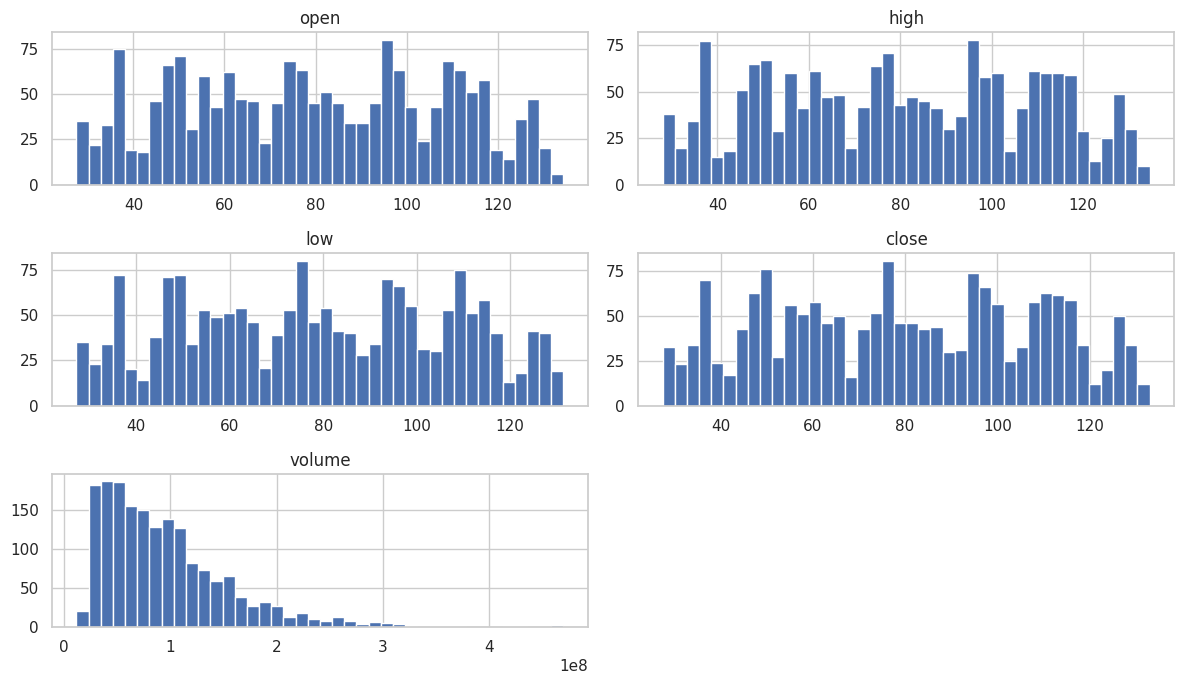

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0,0].plot(stock.date, stock.close); axes[0,0].set_title(TICKER+' closing price')
axes[0,1].plot(stock.date, stock.volume); axes[0,1].set_title('Volume')
stock.close.pct_change(fill_method=None).hist(bins=60, ax=axes[1,0]); axes[1,0].set_title('Daily returns')
sns.heatmap(stock[features].corr(), annot=True, fmt='.2f', ax=axes[1,1])
plt.tight_layout(); plt.savefig(OUT/'regression_eda.png', dpi=140); plt.show()
stock[features].hist(figsize=(12,7), bins=40); plt.tight_layout(); plt.show()

## 4. Target and chronological splits
Shift by one observed trading day. Purge the boundary observation so no training label falls in validation, and no validation label falls in test. Preprocessing is fitted on training data only.

In [14]:
stock['target'] = stock.close.shift(-1)
stock['target_date'] = stock.date.shift(-1)
stock = stock.dropna(subset=['target']).reset_index(drop=True)
a, b = int(.70*len(stock)), int(.85*len(stock))
train = stock.iloc[:a-1].copy(); valid = stock.iloc[a:b-1].copy(); test = stock.iloc[b:].copy()
assert train.target_date.max() < valid.date.min()
assert valid.target_date.max() < test.date.min()
Xtr_raw, Xva_raw, Xte_raw = [s[features] for s in [train, valid, test]]
ytr_raw, yva_raw, yte_raw = [s.target.to_numpy(np.float32).reshape(-1,1) for s in [train, valid, test]]
preprocessor = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
Xtr = preprocessor.fit_transform(Xtr_raw).astype('float32')
Xva = preprocessor.transform(Xva_raw).astype('float32'); Xte = preprocessor.transform(Xte_raw).astype('float32')
yscaler = StandardScaler().fit(ytr_raw)
ytr, yva = [yscaler.transform(y).astype('float32') for y in [ytr_raw, yva_raw]]
for name, s in [('train',train),('validation',valid),('test',test)]:
    print(name, len(s), s.date.min(), s.date.max())

train 1231 2010-01-04 00:00:00 2014-11-20 00:00:00
validation 263 2014-11-24 00:00:00 2015-12-09 00:00:00
test 265 2015-12-11 00:00:00 2016-12-29 00:00:00


## 5. PyTorch MLP and reusable training loop
Validation curves are computed in evaluation mode, with dropout disabled. Loss is scaled-target MSE; final errors will be in original price units.

In [15]:
class MLP(nn.Module):
    def __init__(self, input_dim, output_dim=1, hidden_sizes=(64, 32), dropout=0.0):
        super().__init__()
        layers = []; previous = input_dim
        for width in hidden_sizes:
            layers += [nn.Linear(previous, width), nn.ReLU(), nn.Dropout(dropout)]
            previous = width
        layers.append(nn.Linear(previous, output_dim))
        self.layers = nn.Sequential(*layers)
    def forward(self, x): return self.layers(x)

def float32_array(x): return np.asarray(x, dtype=np.float32)

In [16]:
def fit_experiment(Xtr, ytr, Xva, yva, config, classification=False,
                   dropout=0.0, weight_decay=0.0, early_stopping=False):
    seed_all()
    output_dim = len(classes) if classification else 1
    model = MLP(Xtr.shape[1], output_dim, config['hidden_sizes'], dropout).to(DEVICE)
    optimizer = config['optimizer'](model.parameters(), lr=config['lr'], weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss() if classification else nn.MSELoss()
    yt = torch.tensor(ytr, dtype=torch.long if classification else torch.float32)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr, dtype=torch.float32), yt),
                        batch_size=64, shuffle=True)
    def evaluate(X, y):
        model.eval()
        with torch.no_grad():
            output = model(torch.tensor(X, dtype=torch.float32, device=DEVICE))
            target = torch.tensor(y, dtype=torch.long if classification else torch.float32, device=DEVICE)
            loss = criterion(output, target).item()
            p = output.argmax(1).cpu().numpy() if classification else output.cpu().numpy()
        metric = accuracy_score(y, p) if classification else r2_score(y, p)
        return loss, metric
    history = []; best_loss = float('inf'); best_state = None; stale = 0
    for epoch in range(config['epochs']):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(); loss = criterion(model(xb), yb)
            loss.backward(); optimizer.step()
        tl, tm = evaluate(Xtr, ytr); vl, vm = evaluate(Xva, yva)
        history.append(dict(epoch=epoch+1, train_loss=tl, val_loss=vl, train_metric=tm, val_metric=vm))
        if vl < best_loss - 1e-6:
            best_loss = vl; best_state = copy.deepcopy(model.state_dict()); stale = 0
        else: stale += 1
        if early_stopping and stale >= 12: break
    if early_stopping: model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

def predict_model(model, X, classification=False):
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(X, dtype=torch.float32, device=DEVICE))
    return out.argmax(1).cpu().numpy() if classification else out.cpu().numpy()

def plot_history(history, name, classification=False):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for split in ['train', 'val']:
        axes[0].plot(history.epoch, history[split+'_loss'], label=split)
        axes[1].plot(history.epoch, history[split+'_metric'], label=split)
    axes[0].set(title=name+' — loss', xlabel='Epoch', ylabel='Cross entropy' if classification else 'MSE (scaled target)')
    axes[1].set(title='Accuracy' if classification else 'R²', xlabel='Epoch')
    for ax in axes: ax.legend()
    plt.tight_layout(); plt.savefig(OUT/(name+'_curves.png'), dpi=140); plt.show()

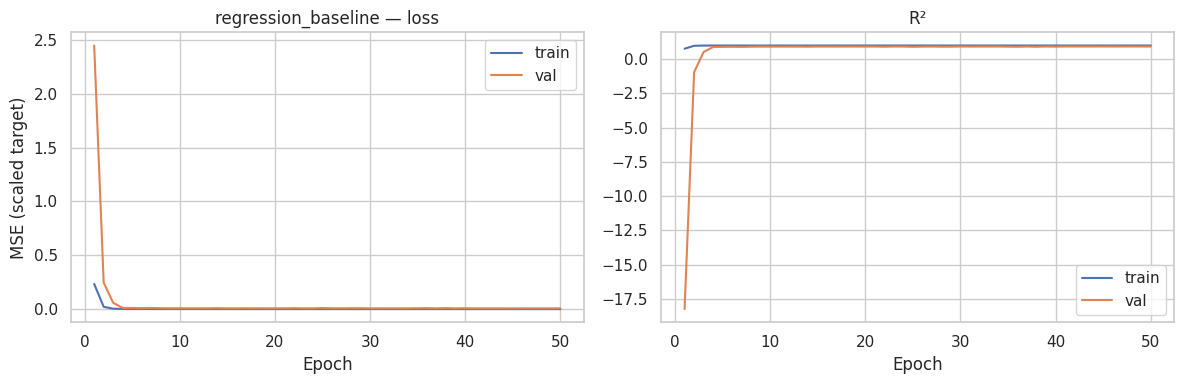

In [20]:
baseline_config = dict(hidden_sizes=(64,32), optimizer=torch.optim.Adam, lr=.001, epochs=50)
base_model, base_history = fit_experiment(Xtr,ytr,Xva,yva,baseline_config)
plot_history(base_history, 'regression_baseline')

## 6. GridSearchCV on training data only
Skorch bridges PyTorch and sklearn. Each fold fits its own feature and target scalers. `gap=1` separates the one-day-ahead labels at CV boundaries. Negative MSE is scored after inverse target transformation. No internal skorch split is needed because CV supplies validation folds.

In [17]:
net = NeuralNetRegressor(MLP, module__input_dim=len(features), criterion=nn.MSELoss,
    train_split=None, batch_size=64, verbose=0, device=DEVICE, iterator_train__shuffle=True)
regressor = Pipeline([
    ('prep', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()),
                       ('float32', FunctionTransformer(float32_array))])),
    ('net', net)])
estimator = TransformedTargetRegressor(regressor=regressor, transformer=StandardScaler())
grid = {
    'regressor__net__lr': [.001, .01],
    'regressor__net__optimizer': [torch.optim.Adam, torch.optim.SGD],
    'regressor__net__max_epochs': [50, 100],
    'regressor__net__module__hidden_sizes': [(64,32), (128,64)],
}
seed_all()
search = GridSearchCV(estimator, grid, cv=TimeSeriesSplit(n_splits=3, gap=1),
                      scoring='neg_mean_squared_error', n_jobs=1, refit=True, error_score='raise')
search.fit(Xtr_raw, ytr_raw)
cv_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
display(cv_results[['params','mean_test_score','std_test_score','rank_test_score']])
cv_results.to_csv(OUT/'regression_grid.csv', index=False)
print('Best parameters:', search.best_params_)
bp = search.best_params_
best_config = dict(lr=bp['regressor__net__lr'], optimizer=bp['regressor__net__optimizer'],
    epochs=bp['regressor__net__max_epochs'], hidden_sizes=bp['regressor__net__module__hidden_sizes'])

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([64])) that is different to the input size (torch.Size([64, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([53])) that is different to the input size (torch.Size([53, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([64])) that is different to the input size (torch.Size([64, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input,

,params,mean_test_score,std_test_score,rank_test_score
2,"{'regressor__net__lr': 0.001, 'regressor__net_...",-725.956970,70.874396,1
4,"{'regressor__net__lr': 0.001, 'regressor__net_...",-730.701558,95.203504,2
11,"{'regressor__net__lr': 0.01, 'regressor__net__...",-731.227722,77.957913,3
7,"{'regressor__net__lr': 0.001, 'regressor__net_...",-733.616923,123.322850,4
15,"{'regressor__net__lr': 0.01, 'regressor__net__...",-734.377747,72.176110,5
0,"{'regressor__net__lr': 0.001, 'regressor__net_...",-735.064657,70.744524,6
6,"{'regressor__net__lr': 0.001, 'regressor__net_...",-741.645996,100.593404,7
13,"{'regressor__net__lr': 0.01, 'regressor__net__...",-742.533162,83.737462,8
8,"{'regressor__net__lr': 0.01, 'regressor__net__...",-746.218872,83.582930,9
1,"{'regressor__net__lr': 0.001, 'regressor__net_...",-750.905823,120.390881,10


Best parameters: {'regressor__net__lr': 0.001, 'regressor__net__max_epochs': 50, 'regressor__net__module__hidden_sizes': (128, 64), 'regressor__net__optimizer': <class 'torch.optim.adam.Adam'>}


## 7. Regularization comparison
Keep all other settings fixed. Early stopping has patience 12 and restores the lowest-validation-loss checkpoint. Select the final experiment by validation RMSE, then evaluate frozen models on test once.

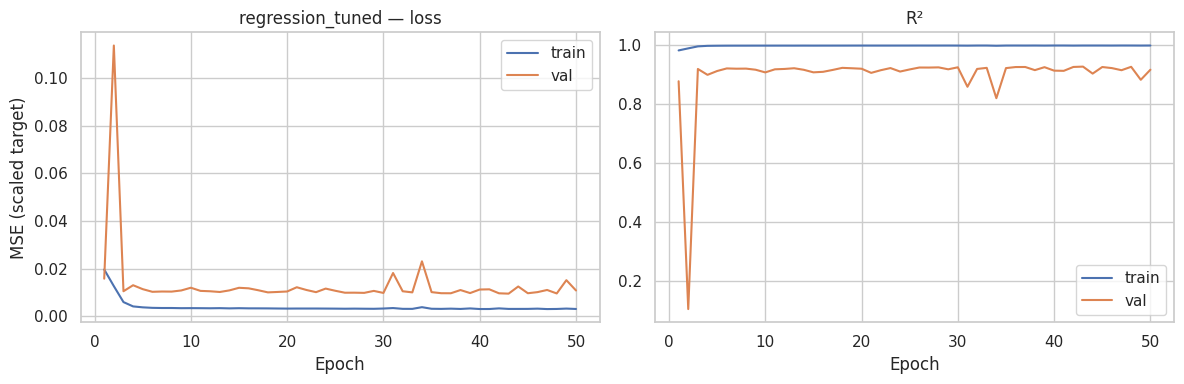

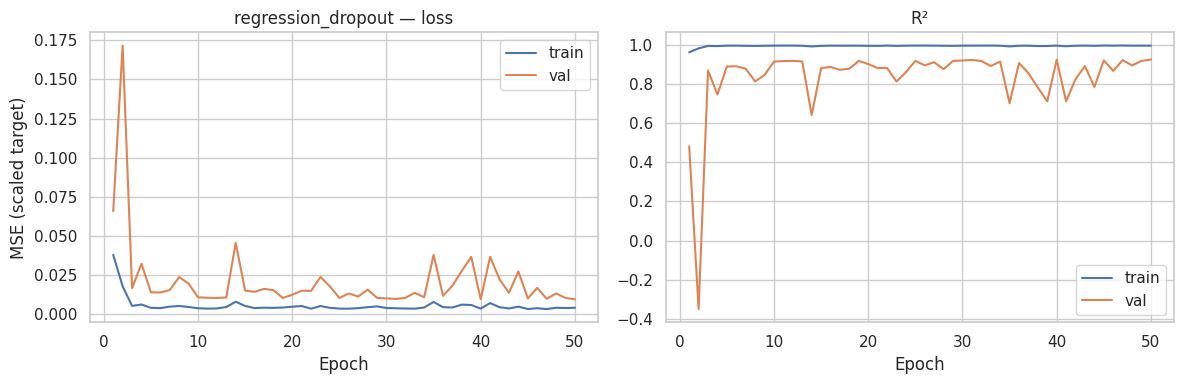

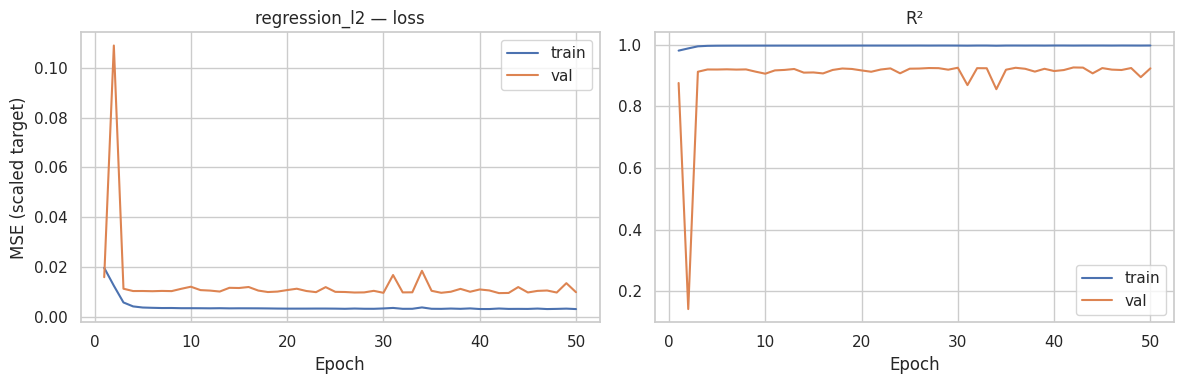

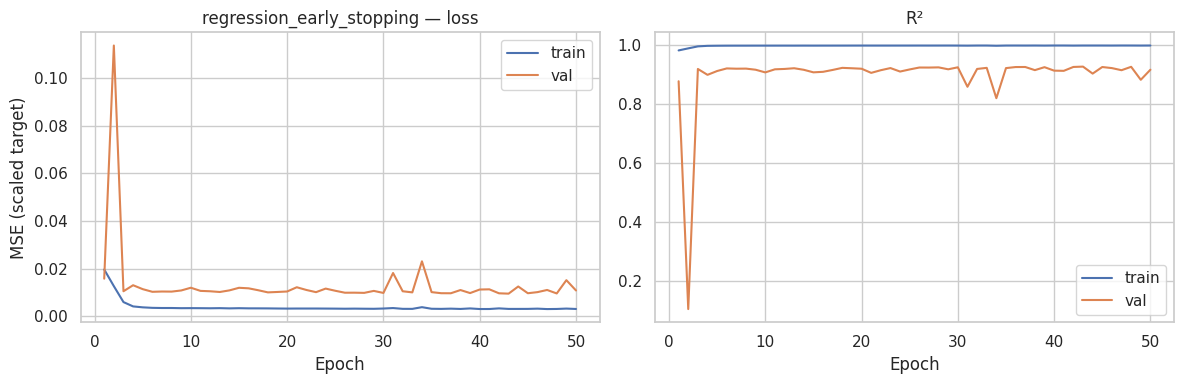

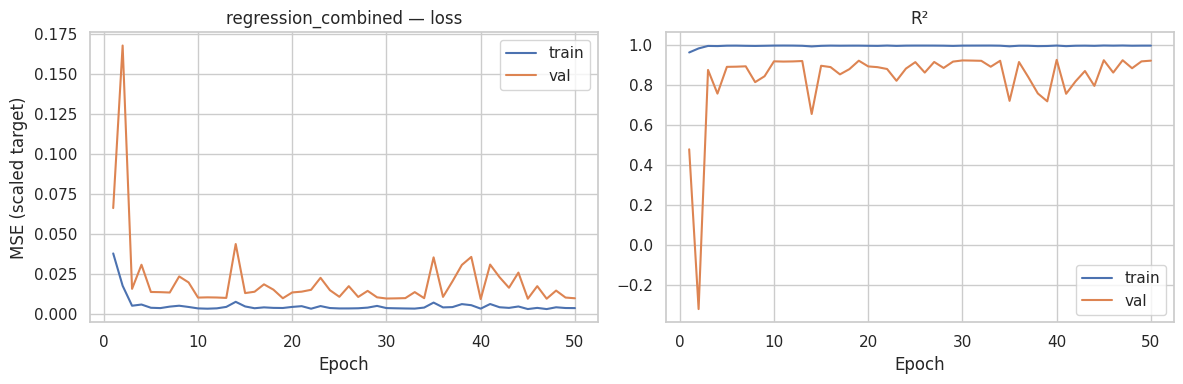

,model,epochs,MAE,RMSE,R2
4,early_stopping,50,1.553319,2.013744,0.925695
2,dropout,50,1.569997,2.023026,0.925008
5,combined,50,1.554137,2.023386,0.924981
3,l2,50,1.578377,2.050562,0.922953
0,baseline,50,1.614152,2.102693,0.918985
1,tuned,50,1.663438,2.150713,0.915243


Frozen selection: early_stopping


In [21]:
experiments = {'baseline': (base_model, base_history)}
variants = {'tuned': {}, 'dropout': {'dropout':.2}, 'l2':{'weight_decay':1e-4},
            'early_stopping':{'early_stopping':True},
            'combined':{'dropout':.2,'weight_decay':1e-4,'early_stopping':True}}
for name, kwargs in variants.items():
    experiments[name] = fit_experiment(Xtr,ytr,Xva,yva,best_config,**kwargs)
    plot_history(experiments[name][1], 'regression_'+name)
def regression_metrics(y,p):
    return dict(MAE=mean_absolute_error(y,p), RMSE=np.sqrt(mean_squared_error(y,p)), R2=r2_score(y,p))
validation_rows = []
for name,(m,h) in experiments.items():
    p = yscaler.inverse_transform(predict_model(m,Xva))
    validation_rows.append(dict(model=name, epochs=len(h), **regression_metrics(yva_raw,p)))
validation_table = pd.DataFrame(validation_rows).sort_values('RMSE')
display(validation_table)
selected_name = validation_table.iloc[0]['model']; print('Frozen selection:', selected_name)

## 8. Final train/test metrics and forecast plots
Do not use this table to tune further. Compare against persistence: tomorrow’s close equals today’s close.

,model,split,MAE,RMSE,R2
0,baseline,train,0.833463,1.175566,0.996781
1,baseline,test,1.154286,1.603369,0.954216
2,tuned,train,0.817246,1.137270,0.996987
3,tuned,test,1.157062,1.594612,0.954715
4,dropout,train,1.012271,1.337627,0.995832
5,dropout,test,1.067378,1.506722,0.959569
6,l2,train,0.810304,1.136992,0.996989
7,l2,test,1.104004,1.543980,0.957545
8,early_stopping,train,0.811620,1.141612,0.996964
9,early_stopping,test,1.095376,1.528409,0.958397


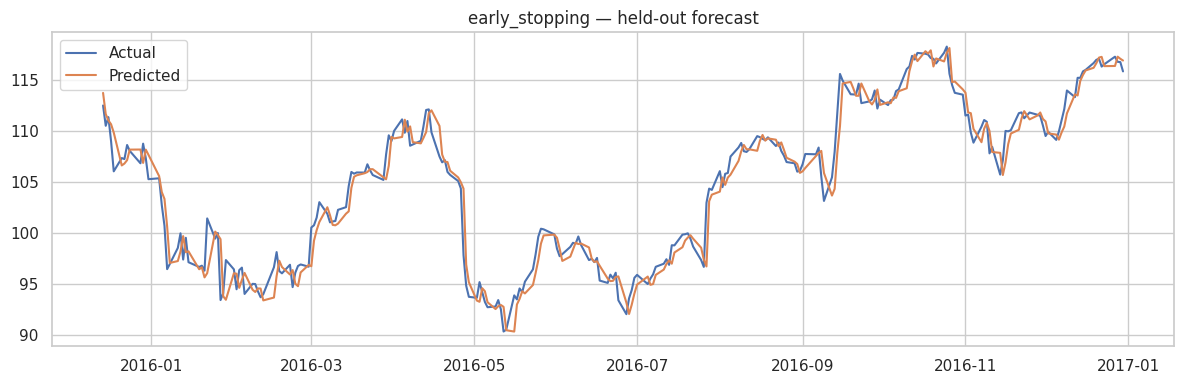

In [22]:
rows=[]
for name,(m,h) in experiments.items():
    h.to_csv(OUT/(name+'_history.csv'),index=False)
    for split,X,y in [('train',Xtr,ytr_raw),('test',Xte,yte_raw)]:
        pred = yscaler.inverse_transform(predict_model(m,X))
        rows.append(dict(model=name,split=split,**regression_metrics(y,pred)))

for split,s in [('train',train),('test',test)]:
    rows.append(dict(model='persistence',split=split,**regression_metrics(s.target,s.close)))

results = pd.DataFrame(rows); display(results)
results.to_csv(OUT/'regression_metrics.csv',index=False)
chosen = experiments[selected_name][0]
pred = yscaler.inverse_transform(predict_model(chosen,Xte)).ravel()
plt.figure(figsize=(12,4)); plt.plot(test.target_date,yte_raw.ravel(),label='Actual')
plt.plot(test.target_date,pred,label='Predicted'); plt.legend(); plt.title(selected_name+' — held-out forecast')
plt.tight_layout(); plt.savefig(OUT/'regression_forecast.png',dpi=140); plt.show()
pd.DataFrame({'date':test.target_date,'actual':yte_raw.ravel(),'predicted':pred}).to_csv(OUT/'predictions.csv',index=False)
torch.save(chosen.cpu().state_dict(), OUT/'regression_weights.pt')

## Interpretation and synthesis — complete after running
1. Which hyperparameters won? Report mean CV score and variation across folds.
2. Do validation curves show overfitting, underfitting or unstable optimization?
3. Which regularization method improved validation performance? Was it consistent with final test results?
4. Compare the MLP against the simple baseline. Discuss limitations and rare-class behavior where applicable.
5. Explain what you learned about PyTorch tensors, MLPs, preprocessing, leakage, GridSearchCV and regularization.

**Learning curves:** validation curves guide selection. The assignment requests test curves, but repeated test-driven selection biases evaluation. The optional frozen replay below provides literal train/test curves after all choices are locked. Do not change model settings after seeing them.

**GitHub:** download this executed notebook and the results ZIP, add dataset links, installation instructions, actual comparison tables and your synthesis to README.md. Do not publish Kaggle credentials. Model weights alone require the matching architecture and fitted preprocessing for deployment; this lab does not package an inference service.

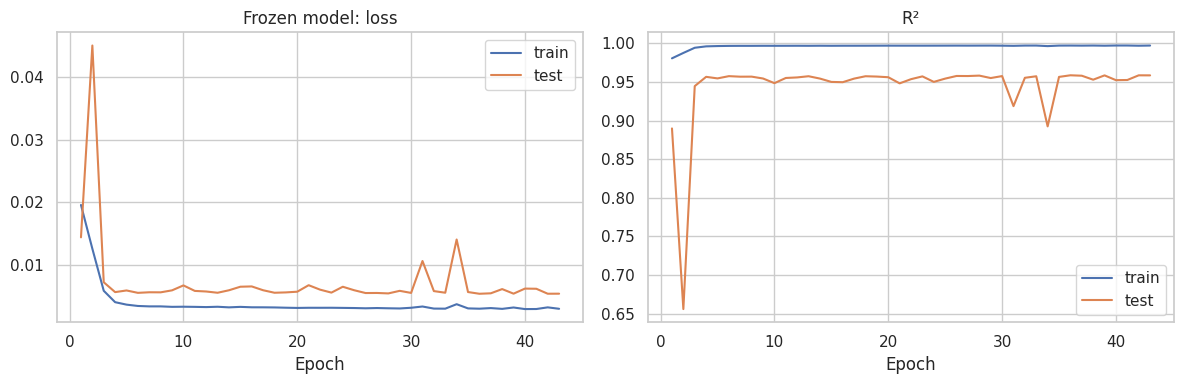

In [23]:
# Optional assignment figure: frozen train/test learning curves.
# This deterministic replay does NOT select settings or stop based on test data.
RUN_TEST_CURVES = True
if RUN_TEST_CURVES:
    is_classification = False
    original_model, original_history = experiments[selected_name]
    cfg = dict(baseline_config if selected_name in ['baseline','random_oversampling','synthetic_baseline'] else best_config)
    frozen_epochs = len(original_history)
    if selected_name in ['early_stopping','combined']:
        frozen_epochs = int(original_history.loc[original_history.val_loss.idxmin(),'epoch'])

    drop = .2 if selected_name in ['dropout','combined'] else 0.
    wd = 1e-4 if selected_name in ['l2','combined'] else 0.
    seed_all()
    replay = MLP(Xtr.shape[1],len(classes) if is_classification else 1,cfg['hidden_sizes'],drop).to(DEVICE)
    opt = cfg['optimizer'](replay.parameters(),lr=cfg['lr'],weight_decay=wd)
    loss_fn = nn.CrossEntropyLoss() if is_classification else nn.MSELoss()
    fitX,fity=Xtr,ytr
    test_y=yscaler.transform(yte_raw).astype('float32')
    dtype = torch.long if is_classification else torch.float32
    batches = DataLoader(TensorDataset(torch.tensor(fitX,dtype=torch.float32),torch.tensor(fity,dtype=dtype)),batch_size=64,shuffle=True)
    records=[]

    for epoch in range(frozen_epochs):
        replay.train()
        for xb,yb in batches:
            opt.zero_grad(); loss=loss_fn(replay(xb.to(DEVICE)),yb.to(DEVICE)); loss.backward(); opt.step()
        replay.eval(); row={'epoch':epoch+1}
        for split,xx,yy in [('train',Xtr,ytr),('test',Xte,test_y)]:
            with torch.no_grad():
                out=replay(torch.tensor(xx,dtype=torch.float32,device=DEVICE))
                row[split+'_loss']=loss_fn(out,torch.tensor(yy,dtype=dtype,device=DEVICE)).item()
                pp=out.argmax(1).cpu().numpy() if is_classification else out.cpu().numpy()

            row[split+'_metric']=accuracy_score(yy,pp) if is_classification else r2_score(yy,pp)
        records.append(row)
    curves=pd.DataFrame(records)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for split in ['train','test']:
        axes[0].plot(curves.epoch,curves[split+'_loss'],label=split)
        axes[1].plot(curves.epoch,curves[split+'_metric'],label=split)

    axes[0].set_title('Frozen model: loss'); axes[1].set_title('Accuracy' if is_classification else 'R²')
    for ax in axes: ax.set_xlabel('Epoch'); ax.legend()
    plt.tight_layout(); plt.savefig(OUT/'frozen_train_test_curves.png',dpi=140); plt.show()
    curves.to_csv(OUT/'frozen_train_test_history.csv',index=False)


## Export results
Download the ZIP and save the executed notebook using **File → Download → Download .ipynb**. The ZIP contains figures, per-epoch histories, grid-search results and metrics.

In [24]:
import shutil
from pathlib import Path
from google.colab import files

OUT = Path('results')
OUT.mkdir(exist_ok=True)

shutil.make_archive('regression_results', 'zip', OUT)
files.download('regression_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>